### Gold r_norm for chronic SBP drift (LINK): Drift-fix version

*Post 2 of 3 in the Ephys Signal series. Post 1 established the drift problem in raw SBP. This notebook applies and evaluates the proposed fix. Post 3 places these results in the context of the broader BCI nonstationarity literature.*

Does Gold-layer normalization using `r_norm` make chronic Utah-array SBP features stable enough for cross-day decoding without per-day recalibration?

The notebook:

- loads LINK chronic SBP features from the released NWB structure,
- applies the `Gold r_norm` normalization as the proposed drift correction,
- quantifies whether raw-to-normalized stability improves cross-day feature consistency, and
- tests cross-day decoder transfer for both signal/feature sanity and behaviorally meaningful performance changes.

**Dataset:** LINK (DANDI 001201), using all local `*.nwb` files in `01_data`

**Outputs:** figures, decoder-transfer tables, and appendix diagnostics that document the main claim and key side checks confirming the fix doesn't just inflate metrics.

## 1. Data calling (LINK SBP/velocity + QC)

The next three code cells make the notebook runnable from either the repo root or `03_notebooks`, initialize figure export, and discover all LINK NWB files currently available in `01_data` (via `get_data_dir()`). The analysis below treats those local files as the working dataset for this report.

In [1]:
# ── All imports ───────────────────────────────────────────────────────────────
import sys
from pathlib import Path

# Add 02_package/src before neurosignal (repo root or 03_notebooks)
_root = Path.cwd()
if not (_root / "02_package" / "src").is_dir():
    _root = _root.parent
pkg_src = _root / "02_package" / "src"
if pkg_src.is_dir() and str(pkg_src) not in sys.path:
    sys.path.insert(0, str(pkg_src))

from neurosignal.io.loaders import get_repo_root

ROOT = get_repo_root()

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pynwb import NWBHDF5IO
from scipy.ndimage import gaussian_filter1d
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.model_selection import cross_val_score
from sklearn.metrics import r2_score

In [2]:
# Figure export: serial numbering and registry (see 04_output/research/output/README_figures.md)
import sys
from pathlib import Path

_root = Path.cwd()
if not (_root / "02_package" / "src").is_dir():
    _root = _root.parent
_pkg = _root / "02_package" / "src"
if _pkg.is_dir() and str(_pkg) not in sys.path:
    sys.path.insert(0, str(_pkg))

from neurosignal.viz import init_figure_export, save_figure, get_figure_registry
from neurosignal.io.loaders import get_repo_root

# Define OUT_DIR here so this cell is safe to run in any order
ROOT = get_repo_root()
OUT_DIR = ROOT / "04_output"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Match on-disk figures_supporting subfolder (serial prefix + slug)
NOTEBOOK_FIG_ID = "02_sbp-drift-fix"
FIG_SUPPORT_DIR = OUT_DIR / "figures_supporting" / NOTEBOOK_FIG_ID
FIG_SUPPORT_DIR.mkdir(parents=True, exist_ok=True)

init_figure_export(OUT_DIR, notebook_id=NOTEBOOK_FIG_ID, subdir="figures_supporting", reset=True)

In [3]:
# Run from repo root or from 03_notebooks; DATA_DIR from get_data_dir().
import sys
from pathlib import Path

_root = Path.cwd()
if not (_root / "02_package" / "src").is_dir():
    _root = _root.parent
_pkg = _root / "02_package" / "src"
if _pkg.is_dir() and str(_pkg) not in sys.path:
    sys.path.insert(0, str(_pkg))

from neurosignal.io.loaders import get_repo_root, get_data_dir

ROOT = get_repo_root()
DATA_DIR = get_data_dir()
OUT_DIR = ROOT / "04_output"
OUT_DIR.mkdir(parents=True, exist_ok=True)

NOTEBOOK_FIG_ID = "02_sbp-drift-fix"
FIG_SUPPORT_DIR = OUT_DIR / "figures_supporting" / NOTEBOOK_FIG_ID
FIG_SUPPORT_DIR.mkdir(parents=True, exist_ok=True)

nwb_files = sorted(DATA_DIR.glob("*.nwb"))
NWB_PATHS = nwb_files if nwb_files else [DATA_DIR / "sub-Monkey-N_ses-20200130_ecephys.nwb"]
print(f"Found {len(NWB_PATHS)} sessions")

Found 30 sessions


### Data source (raw LINK) + QC policy

We treat the released LINK NWB files in `01_data` as raw chronic input (no cross-day alignment step expected here). The next cells load session-wise SBP + velocity and apply per-session QC, dropping outlier sessions globally.

In [4]:
# NWB structure/alignment diagnostics live in sbp-drift-discovery_v1.ipynb.
print(f"Input set: raw LINK NWB files from {DATA_DIR.name}/ (QC + r_norm below).")

Input set: raw LINK NWB files from 01_data/ (QC + r_norm below).


### Skipped NWB diagnostics (see discovery)

This fix notebook focuses on the proposed `Gold r_norm` representation. Raw-vs-aligned inspection is documented in the discovery notebook.

In [5]:
# Alignment/processing inspection removed for lean flow.
pass

### Session loading (SBP/velocity) and QC

Load session-wise SBP features and velocity targets, then apply per-session QC and drop flagged sessions globally before any decoder evaluation.

In [6]:
assert NWB_PATHS, "Run data calling first — NWB_PATHS is empty."
from neurosignal.io.loaders import load_link_sessions, session_date_from_path

paths_sorted = sorted(NWB_PATHS, key=session_date_from_path)
sessions_sbp, sessions_vel, session_dates = load_link_sessions(paths_sorted)
N = len(session_dates)
assert N >= 2, "Need at least 2 sessions."

In [7]:
# QC: per-session SBP sanity checks and automatic outlier flagging
# Policy: auto-only QC, and drop flagged sessions from ALL downstream analyses.
from neurosignal.gold import qc_sbp_sessions, filter_sessions_by_bad_dates

_df_qc, _bad_dates = qc_sbp_sessions(
    sessions_sbp,
    sessions_vel,
    session_dates,
    z_thresh=3.5,
)
BAD_SESSION_DATES = sorted(set(_bad_dates))
print("Per-session QC summary:")
print(_df_qc.to_string(index=False))
print("\nQC-flagged bad dates (dropped everywhere):", BAD_SESSION_DATES)

# Filter sessions so flagged sessions cannot affect training/eval/plots.
_drop_idx = [i for i, d in enumerate(session_dates) if d in set(BAD_SESSION_DATES)]
if _drop_idx:
    print(f"\nDropping {len(_drop_idx)} session(s):")
    for i in _drop_idx:
        print(f"  Day {i} | {session_dates[i]}")

sessions_sbp, sessions_vel, session_dates, _keep_idx = filter_sessions_by_bad_dates(
    sessions_sbp,
    sessions_vel,
    session_dates,
    BAD_SESSION_DATES,
)
paths_sorted = [paths_sorted[i] for i in _keep_idx]

N = len(session_dates)
print(f"\nRemaining sessions after QC drop: {N}")

# Keep QC_BAD_SESSION_DATES empty downstream (we already removed those sessions).
QC_BAD_SESSION_DATES = set()


Per-session QC summary:
 k     date  frac_active  r2_intra_raw  pop_raw_mean  pop_raw_std  frac_zero_var_channels  frac_all_nan_channels  z_frac_active  z_r2_intra_raw  z_pop_raw_std  is_qc_outlier
 0 20200127          1.0      0.143585      3.939605     0.295072                     0.0                    0.0            0.0        1.768929       0.591965          False
 1 20200130          1.0      0.100815      3.993986     0.308984                     0.0                    0.0            0.0       -0.459473       0.851709          False
 2 20200204          1.0      0.119565      3.916844     0.316526                     0.0                    0.0            0.0        0.517465       0.992510          False
 3 20200205          1.0      0.099165      4.096604     0.352178                     0.0                    0.0            0.0       -0.545438       1.658147          False
 4 20200206          1.0      0.108095      3.910669     0.315602                     0.0                 

In [8]:
# Qualitative trace sanity-check later in the notebook expects `model`.
# We compute the raw SBP Day-0 model here, but skip the discovery plots.
from neurosignal.gold import compute_decoder_r2_per_day

_, model = compute_decoder_r2_per_day(sessions_sbp, sessions_vel)

## 2. Gold r_norm: proposed solution

The candidate representation is `Gold r_norm`: per-channel, per-session z-scoring followed by 50 ms Gaussian smoothing. In paper language, the goal is to remove session-specific gain and variance drift while preserving the 96-channel structure that a linear decoder uses.

For channel `i` in session `d`:

$$
z_{i,d}(t) = \frac{\mathrm{SBP}_{i,d}(t)-\mu_{i,d}}{\sigma_{i,d}}, \qquad
r_{i,d}(t) = (z_{i,d} * h)(t), \quad h \sim \mathcal{N}(0, 50\,\mathrm{ms})
$$

### Evaluation protocol

Success is defined by ordered train/test transfer across sessions. The main metric is pairwise `R^2`: diagonal entries measure within-session decoding, while off-diagonal entries test cross-day transfer. The notebook then checks four questions in order: does `Gold r_norm` fix transfer, which component matters, does the gain persist across time gaps, and do decoded traces remain behaviorally sensible?

### Results

#### 2.1 Does Gold r_norm fix cross-day transfer?

The first comparison below is the headline result: raw SBP versus `Gold r_norm` under the same decoder family.

### Plot 2A setup: feature variants

Build the normalized feature variants used for cross-session pairwise decoder transfer.
This cell prepares inputs only; it does not yet run the expensive pairwise R² sweep.

In [9]:
# ----- Plot 2A: Pairwise R² — Raw vs r_norm ----

import pandas as pd
from neurosignal.gold import (
    compute_pairwise_r2_matrix,
    mask_bad_sessions,
    normalize_sessions_sbp_gold,
    plot_pairwise_r2_raw_vs_norm,
    quantify_norm_improvement,
)

R2_PLOT_FLOOR = -5.0
QC_BAD_SESSION_DATES = set()
QC_BAD_SESSION_IDX = []

# Raw SBP → static decoder (cold off-diagonals)
R_pairwise = compute_pairwise_r2_matrix(sessions_sbp, sessions_vel)

# Gold r_norm feature variant
sessions_sbp_gold = normalize_sessions_sbp_gold(sessions_sbp, sigma_bins=2.5)


### Plot 2A compute: pairwise R² matrices

This is the expensive step. Run it once per feature set, then reuse the resulting matrices for tables and figures below.

In [10]:
R_pairwise_gold = compute_pairwise_r2_matrix(sessions_sbp_gold, sessions_vel)

R_pairwise_qc = mask_bad_sessions(R_pairwise, QC_BAD_SESSION_IDX)
R_pairwise_gold_qc = mask_bad_sessions(R_pairwise_gold, QC_BAD_SESSION_IDX)


### Plot 2A summary: off-diagonal improvement

Quantify how much `r_norm` improves cross-session transfer relative to the raw static baseline.
The table below is the numeric companion to the heatmap.

In [11]:
# Quantify improvement: table + mean off-diagonal delta
df_norm_improvement = quantify_norm_improvement(R_pairwise_qc, R_pairwise_gold_qc, session_dates)
display(df_norm_improvement)
delta = df_norm_improvement.attrs.get("mean_off_diagonal_delta", None)
if delta is not None:
    print(f"Mean off-diagonal Δ R² (r_norm − raw, QC-masked): {delta:.4f}")
df_norm_improvement.to_csv(FIG_SUPPORT_DIR / "norm_improvement.csv", index=False)


,Day K,Date,R²_raw,R²_norm,Δ R² (norm − raw)
0,0,20200127,0.3226,0.3409,0.0183
1,1,20200130,-0.4322,0.1656,0.5979
2,2,20200204,-0.8900,0.1747,1.0646
3,3,20200205,-0.7294,0.1869,0.9163
4,4,20200206,-1.3707,0.1617,1.5324
5,5,20200211,-0.4583,0.1960,0.6543
6,6,20200222,-0.3588,0.0702,0.4290
7,7,20200224,-0.6292,0.1125,0.7416
8,8,20200225,-3.9700,0.0259,3.9959
9,9,20200228,-0.0659,0.1554,0.2213


Mean off-diagonal Δ R² (r_norm − raw, QC-masked): 0.9371


### Plot 2A figure: raw vs r_norm heatmap

This is the headline visual for the section: raw SBP produces cold off-diagonals, whereas `r_norm` preserves warmer cross-day transfer structure.

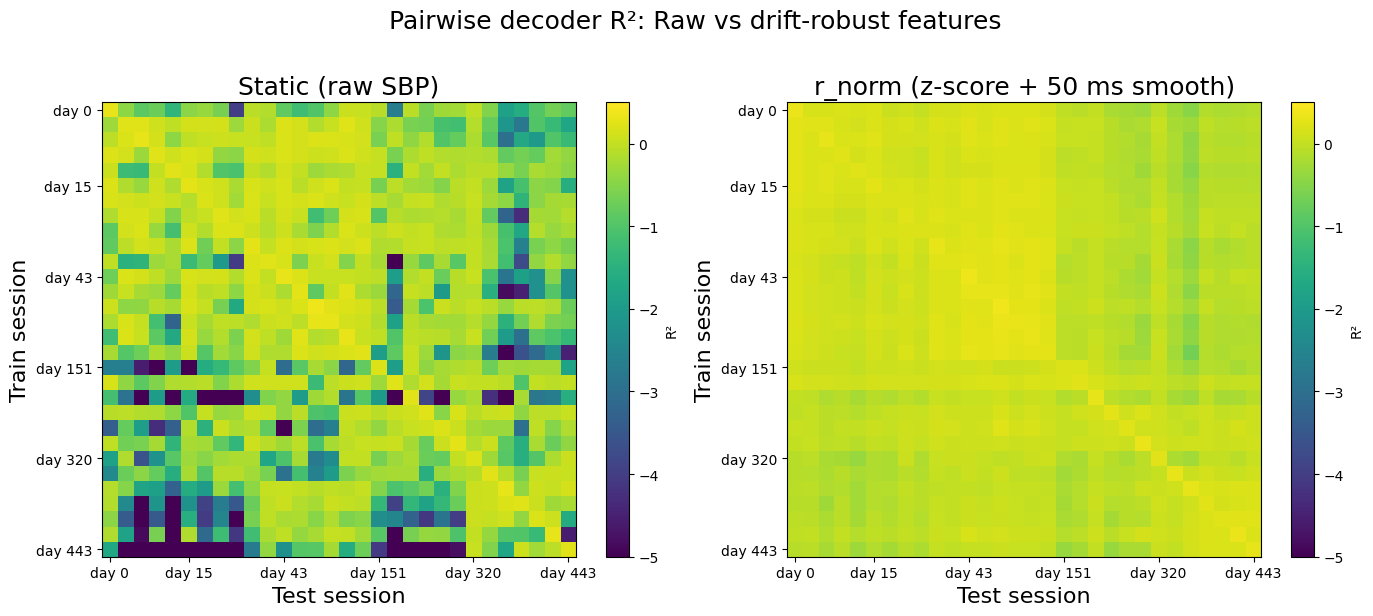

In [12]:
fig = plot_pairwise_r2_raw_vs_norm(
    R_pairwise_qc,
    R_pairwise_gold_qc,
    session_dates,
    title_raw="Static (raw SBP)",
    title_norm="r_norm (z-score + 50 ms smooth)",
    clip_floor=R2_PLOT_FLOOR,
    cmap="viridis",
)
save_figure(fig, "signal_decoder_demo", "pairwise_r2_raw_vs_gold", role="candidate_supporting")
plt.show()

#### 2.2 Which part of Gold r_norm matters?

The next blocks separate several mechanisms: z-score-only normalization, robust median/MAD variants, distribution-level diagnostics, channel yield, and a couple of secondary baselines. The goal is to identify whether the benefit comes mainly from normalization itself, from smoothing, or from something more complicated.

,Day K,Date,R²_raw,R²_norm,Δ R² (norm − raw)
0,0,20200127,0.3226,0.3182,-0.0044
1,1,20200130,-0.4322,0.1854,0.6177
2,2,20200204,-0.8900,0.2229,1.1129
3,3,20200205,-0.7294,0.1602,0.8896
4,4,20200206,-1.3707,0.1558,1.5265
5,5,20200211,-0.4583,0.1929,0.6512
6,6,20200222,-0.3588,0.0916,0.4504
7,7,20200224,-0.6292,0.1230,0.7522
8,8,20200225,-3.9700,0.0576,4.0276
9,9,20200228,-0.0659,0.1669,0.2328


Mean off-diagonal Δ R² (z-score-only − raw, QC-masked): 0.9578


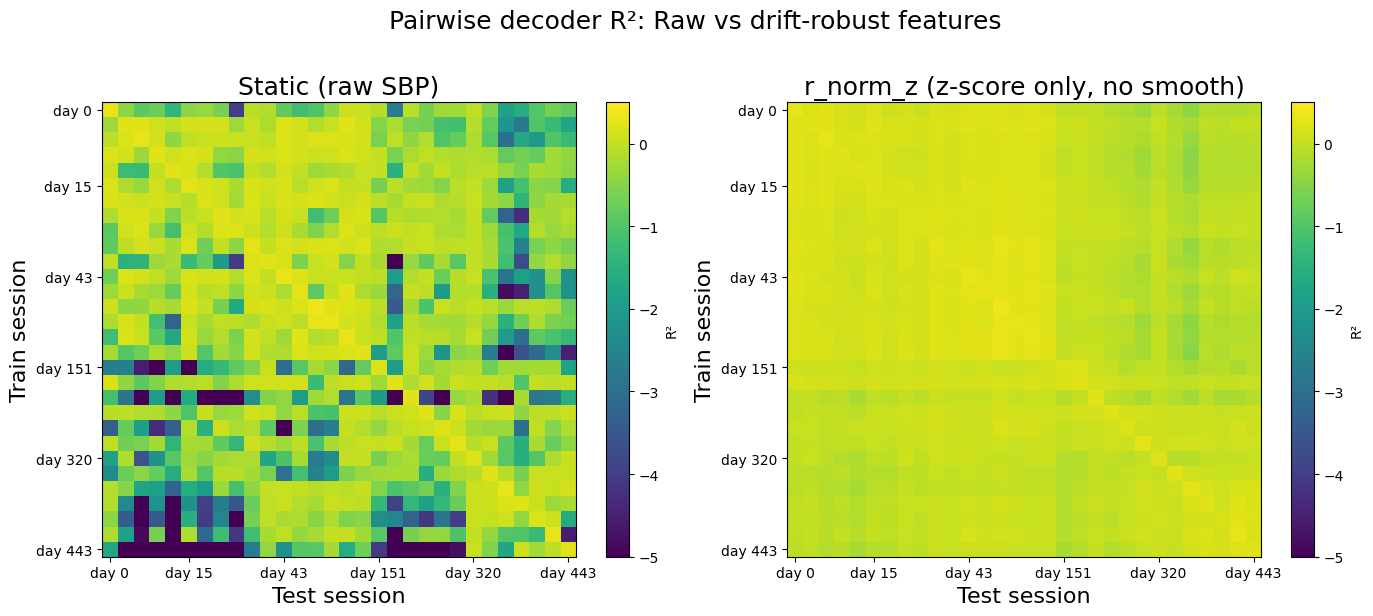

In [13]:
# ----- Plot 2b ablation: z-score only (no temporal smoothing) -----
from neurosignal.gold import (
    compute_pairwise_r2_matrix,
    mask_bad_sessions,
    normalize_sessions_sbp_zscore_only,
    plot_pairwise_r2_raw_vs_norm,
    quantify_norm_improvement,
)

# r_norm_z: per-channel per-day z-score only (no Gaussian smoothing)
# Assumes `sessions_sbp`, `sessions_vel`, `session_dates`, and `OUT_DIR` already defined.

sessions_sbp_z = normalize_sessions_sbp_zscore_only(sessions_sbp)
R_pairwise_z = compute_pairwise_r2_matrix(sessions_sbp_z, sessions_vel)
R_pairwise_z_qc = mask_bad_sessions(R_pairwise_z, QC_BAD_SESSION_IDX)

# Quantify improvement for z-score only vs raw
df_norm_improvement_z = quantify_norm_improvement(R_pairwise_qc, R_pairwise_z_qc, session_dates)
display(df_norm_improvement_z)
delta_z = df_norm_improvement_z.attrs.get("mean_off_diagonal_delta", None)
if delta_z is not None:
    print(f"Mean off-diagonal Δ R² (z-score-only − raw, QC-masked): {delta_z:.4f}")
df_norm_improvement_z.to_csv(FIG_SUPPORT_DIR / "norm_improvement_zscore_only.csv", index=False)

# Side-by-side heatmaps (Static vs r_norm_z)
fig_z = plot_pairwise_r2_raw_vs_norm(
    R_pairwise_qc,
    R_pairwise_z_qc,
    session_dates,
    title_raw="Static (raw SBP)",
    title_norm="r_norm_z (z-score only, no smooth)",
    clip_floor=R2_PLOT_FLOOR,
    cmap="viridis",
)
save_figure(fig_z, "signal_decoder_demo", "pairwise_r2_raw_vs_zscore_only", role="candidate_supporting")
plt.show()

#### 2.3 Does the gain persist across time gaps?

A useful chronic representation must remain helpful beyond adjacent sessions. The table below summarizes decoder performance across intra-day, short-gap, and month-scale transfer horizons to test whether the gain survives increasing train-test separation.

In [14]:
from neurosignal.gold.drift import decoder_comparison_table

# Optional: load with TCR for raw_mean(TCR) and pop_rate_norm(TCR)
# sessions_sbp, sessions_tcr, sessions_vel, session_dates = load_link_sessions(paths_sorted, include_tcr=True)
# df_dec = decoder_comparison_table(sessions_sbp, sessions_vel, session_dates, sessions_tcr=sessions_tcr, include_robust=True)

df_dec = decoder_comparison_table(
    sessions_sbp,
    sessions_vel,
    session_dates,
    sessions_tcr=None,
    include_robust=True,
    robust_block_size_bins=250,
)
display(df_dec)
df_dec.to_csv(FIG_SUPPORT_DIR / "decoder_comparison_by_horizon.csv", index=False)

,feature_set,intra_day,1_7_days,1_month_plus
0,r_norm,0.3409,0.1656,-0.0410
1,raw_mean,0.0007,-0.0009,-0.0050
2,pop_rate_norm,0.0098,-0.0100,-0.0099
3,r_norm_robust_session,0.3407,0.1656,-0.0493
4,r_norm_robust_block,0.3352,0.1710,-0.0392
5,pop_rate_norm_robust_session,0.0095,-0.0093,-0.0108
6,pop_rate_norm_robust_block,0.0093,-0.0086,-0.0105


#### 2.4 Do decoded traces remain behaviorally sensible?

Numerical improvements matter only if the decoded trajectories still look like movement. The next figures compare early and late sessions to check whether `Gold r_norm` preserves sign, timing, and qualitative movement structure rather than merely shifting summary metrics.

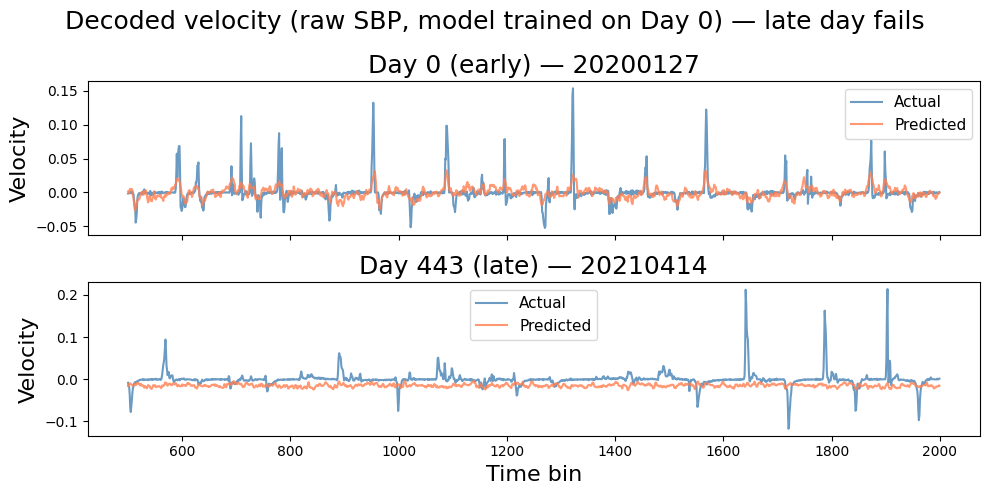

In [15]:
# ----- Plot 2c: Decoded velocity traces — raw SBP (late day fails) -----
from neurosignal.gold.drift import compute_decoder_r2_per_day
from neurosignal.gold.drift_plots import plot_decoded_traces_early_late

# Raw SBP: model trained on Day 0; late-day predictions are flat (expected)
fig = plot_decoded_traces_early_late(
    model, sessions_sbp, sessions_vel, session_dates,
    win=(500, 2000),
    suptitle="Decoded velocity (raw SBP, model trained on Day 0) — late day fails",
)
save_figure(fig, "signal_decoder_demo", "decoded_traces_raw", role="candidate_supporting")
plt.show()

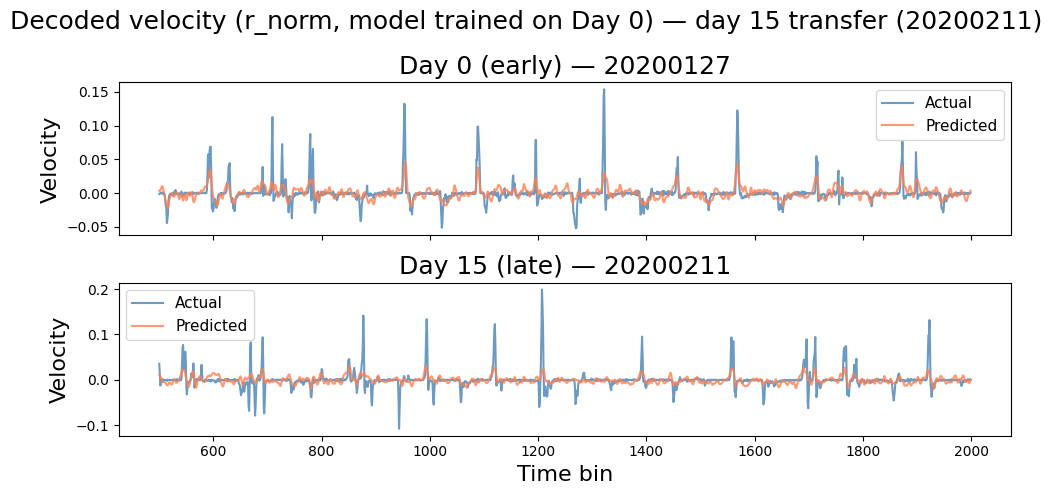

In [16]:
# ----- Plot 2c companion: Decoded velocity traces — r_norm (short-gap recovers) -----
# The function always uses sessions[0] and sessions[-1].
# Pass a sliced list so sessions[-1] is session 5 (2020-02-11, day 15): a short-gap example,
# not the same late session as the raw-SBP figure above (day 443). Month+ failure is in the horizon table.
from neurosignal.gold import compute_decoder_r2_per_day
from neurosignal.gold.drift_plots import plot_decoded_traces_early_late
from neurosignal.gold.drift import compute_day_offsets

LATE_IDX = 5  # session 5 = 20200211, day 15 after Day 0
_, model_gold = compute_decoder_r2_per_day(sessions_sbp_gold, sessions_vel)

fig_gold = plot_decoded_traces_early_late(
    model_gold,
    sessions_sbp_gold[:LATE_IDX + 1],   # [-1] becomes session 5
    sessions_vel[:LATE_IDX + 1],
    session_dates[:LATE_IDX + 1],
    win=(500, 2000),
    suptitle=f"Decoded velocity (r_norm, model trained on Day 0) — day {int(compute_day_offsets(session_dates)[LATE_IDX])} transfer ({session_dates[LATE_IDX]})",
)
save_figure(fig_gold, "signal_decoder_demo", "decoded_traces_gold", role="candidate_supporting")
plt.show()

## 3. Discussion and notebook takeaways

*Every number in this section is read from the cell outputs above, so it updates when the notebook is re-run.*

In [17]:
# ----- Discussion: numbers rendered from the variables above, never typed by hand -----
from IPython.display import Markdown, display
import pandas as pd
from neurosignal.gold.decoder import SPEC
from neurosignal.gold.drift import compute_day_offsets
from neurosignal.io.loaders import get_repo_root

# 95 % CIs: session bootstrap over the same matrices (EXP-003, scripts/exp003_baseline_and_cis.py)
cis = pd.read_csv(get_repo_root() / "results" / f"exp003_cis_{SPEC.spec_id}.csv").set_index("id")
assert abs(float(cis.loc["B1", "value"]) - delta) < 1e-3, "CI file was computed on different matrices"

def ci(k):
    r = cis.loc[k]
    return f"{float(r.value):+.3f} [{float(r.ci_lo):+.3f}, {float(r.ci_hi):+.3f}]"

def holds(k):
    return cis.loc[k, "excludes_zero"] == "yes"

n_sessions = len(session_dates)
span_days = int(compute_day_offsets(session_dates)[-1])

off_raw = df_norm_improvement.attrs["mean_off_diagonal_R2_raw"]
off_gold = df_norm_improvement.attrs["mean_off_diagonal_R2_norm"]

# Day 0 as the training session: how many later sessions decode worse than the mean?
later = df_norm_improvement.iloc[1:]
neg_raw = int((later["R²_raw"] < 0).sum())
neg_gold = int((later["R²_norm"] < 0).sum())

if delta_z < delta:
    ablation_md = (
        f"z-score-only normalization gives a mean off-diagonal Δ R² of **{delta_z:+.3f}**, "
        f"{delta_z / delta:.0%} of the full `r_norm` pipeline (**{delta:+.3f}**). Most of the gain comes from "
        f"the per-channel, per-session standardisation; the 50 ms smoothing adds the remaining {delta - delta_z:+.3f}."
    )
else:
    ablation_md = (
        f"z-score-only normalization gives a mean off-diagonal Δ R² of **{delta_z:+.3f}**, matching or exceeding "
        f"the full `r_norm` pipeline (**{delta:+.3f}**). The gain lives in the per-channel, per-session standardisation; "
        f"the 50 ms smoothing changes mean cross-session R² by {ci('B2')} (95 % CI)"
        + (", so it lowers transfer." if holds("B2") and float(cis.loc["B2", "value"]) < 0 else ", not distinguishable from zero.")
    )

horizon = df_dec.set_index("feature_set")
horizon_rows = [
    ("`r_norm`", "r_norm"),
    ("`r_norm_robust_block`", "r_norm_robust_block"),
    ("Raw mean (1-channel)", "raw_mean"),
]
table_md = "| Feature set | Intra-day R² | 1–7 days R² | 1 month+ R² |\n|---|---:|---:|---:|\n" + "\n".join(
    f"| {label} | {horizon.loc[key, 'intra_day']:.3f} | {horizon.loc[key, '1_7_days']:.3f} | "
    f"**{horizon.loc[key, '1_month_plus']:.3f}** |"
    for label, key in horizon_rows
)

month_gold = horizon.loc["r_norm", "1_month_plus"]
if month_gold < 0:
    month_md = (
        f"At month-scale separation, `r_norm` R² falls to **{month_gold:+.3f}** (mean over {int(cis.loc['B9', 'n'].split()[0])} sessions, 95 % CI {ci('B9').split(' ', 1)[1]})"
        + (": below zero, worse than predicting the mean. " if holds("B9") else ": indistinguishable from zero, so no useful transfer. ")
        + "The short-term drift problem is mostly linear (gain and offset instability, correctable by normalisation), "
        "but long-term drift contains a residual component that normalisation cannot remove."
    )
else:
    month_md = (
        f"At month-scale separation, `r_norm` R² stays positive (**{month_gold:+.3f}**), well below its "
        f"intra-day value of {horizon.loc['r_norm', 'intra_day']:.3f}."
    )

display(Markdown(f"""### What this notebook establishes

The dominant failure mode in this LINK subset is not the absence of a decodable signal, but the instability of raw SBP across sessions. `Gold r_norm` raises the mean off-diagonal R² from **{off_raw:+.3f}** to **{off_gold:+.3f}** (Δ R² **{delta:+.3f}**) across {n_sessions} QC-passed sessions spanning {span_days} days. It reduces the negative-transfer regime rather than eliminating it: with Day 0 as the training session, {neg_raw} of {n_sessions - 1} later sessions score below zero under raw SBP and {neg_gold} under `r_norm`.

The ablation (Section 2.2) separates the two steps. {ablation_md}

**95 % confidence intervals** (session bootstrap, 2,000 draws; `results/exp003_cis_{SPEC.spec_id}.csv`): Δ R² `r_norm` − raw {ci('B1')}; mean off-diagonal R² raw {ci('L-raw')}, `r_norm` {ci('L-r_norm')}, z-score only {ci('L-z_only')}. A difference counts only if its interval excludes zero.

### Where it stops working

The horizon table (Section 2.3) is the honest limit of this result:

{table_md}

{month_md}"""))

### What this notebook establishes

The dominant failure mode in this LINK subset is not the absence of a decodable signal, but the instability of raw SBP across sessions. `Gold r_norm` raises the mean off-diagonal R² from **-0.907** to **+0.030** (Δ R² **+0.937**) across 30 QC-passed sessions spanning 443 days. It reduces the negative-transfer regime rather than eliminating it: with Day 0 as the training session, 27 of 29 later sessions score below zero under raw SBP and 13 under `r_norm`.

The ablation (Section 2.2) separates the two steps. z-score-only normalization gives a mean off-diagonal Δ R² of **+0.958**, matching or exceeding the full `r_norm` pipeline (**+0.937**). The gain lives in the per-channel, per-session standardisation; the 50 ms smoothing changes mean cross-session R² by -0.021 [-0.028, -0.014] (95 % CI), so it lowers transfer.

**95 % confidence intervals** (session bootstrap, 2,000 draws; `results/exp003_cis_v2.csv`): Δ R² `r_norm` − raw +0.937 [+0.576, +1.399]; mean off-diagonal R² raw -0.907 [-1.381, -0.524], `r_norm` +0.030 [-0.012, +0.079], z-score only +0.051 [+0.014, +0.095]. A difference counts only if its interval excludes zero.

### Where it stops working

The horizon table (Section 2.3) is the honest limit of this result:

| Feature set | Intra-day R² | 1–7 days R² | 1 month+ R² |
|---|---:|---:|---:|
| `r_norm` | 0.341 | 0.166 | **-0.041** |
| `r_norm_robust_block` | 0.335 | 0.171 | **-0.039** |
| Raw mean (1-channel) | 0.001 | -0.001 | **-0.005** |

At month-scale separation, `r_norm` R² falls to **-0.041** (mean over 21 sessions, 95 % CI [-0.122, +0.037]): indistinguishable from zero, so no useful transfer. The short-term drift problem is mostly linear (gain and offset instability, correctable by normalisation), but long-term drift contains a residual component that normalisation cannot remove.

### Relation to learned alignment methods

Ma et al. (2023) address exactly this residual using a Cycle-GAN: a bidirectional adversarial network trained on unlabelled same-day recordings that maps day-K neural distributions back into day-0 coordinate space ([*eLife*, 12, e84296](https://doi.org/10.7554/eLife.84296)). Their method maintains decoder accuracy at month-scale gaps where `r_norm` fails.

The relationship between the two approaches is not competitive — it is structural:

- `r_norm` establishes the **floor**: what normalisation alone recovers at zero cost
- Cycle-GAN establishes the **ceiling**: what a trained nonlinear alignment achieves
- The gap between them at 1 month+ quantifies the irreducibly nonlinear component of chronic Utah-array drift

This framing is developed in Post 3.

In [18]:
# ----- Discussion: scope, rendered from the session list -----
display(Markdown(f"""### Scope of this notebook

The evidence here covers {n_sessions} LINK sessions ({session_dates[0]} → {session_dates[-1]}, {span_days} days), SBP features, and linear Ridge-family decoders. The result should be read as a strong unsupervised baseline, not a final alignment system. Later-stage chronic degradation, nonlinear decoders, and combined SBP+TCR representations may shift absolute R² values while leaving the normalization effect intact."""))

### Scope of this notebook

The evidence here covers 30 LINK sessions (20200127 → 20210414, 443 days), SBP features, and linear Ridge-family decoders. The result should be read as a strong unsupervised baseline, not a final alignment system. Later-stage chronic degradation, nonlinear decoders, and combined SBP+TCR representations may shift absolute R² values while leaving the normalization effect intact.